1. Инициализация, просмотр данных, дубликаты и разделение на трейн и тест

In [70]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np

# Надёжно определяем корень репозитория
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

RANDOM_STATE = 43

RAW_PATH = PROJECT_ROOT / "data" / "raw" / "rent_v32.csv"
print("Корень проекта:", PROJECT_ROOT)
print("Файл существует:", RAW_PATH.exists())

Корень проекта: e:\Artyom\sber\lab2\Tyapkov_Artyom_Lab2
Файл существует: True


In [71]:
# Проверяем, в какой кодировке файл читается без ошибок
for enc in ["utf-8-sig", "utf-8", "cp1251", "cp866"]:
    try:
        with open(RAW_PATH, "r", encoding=enc) as f:
            lines = [next(f) for _ in range(7)]
        print(f"=== Кодировка '{enc}' подошла ===")
        for i, line in enumerate(lines):
            print(f"[{i}]: {line.rstrip()}")
        print()
    except UnicodeDecodeError:
        print(f"Кодировка '{enc}' НЕ подошла\n")

=== Кодировка 'utf-8-sig' подошла ===
[0]: listing_id	publication_date	district	house_type	year_built	floors_total	floor	elevator	rooms	total_area	living_area	kitchen_area	ceiling_height	renovation	furniture	appliances	balcony	parking	metro_distance_m	distance_to_center_km	pets_allowed	seller_type	photos_count	owner_rating	response_time_hours	rent_rub
[1]: KV-697625	10.10.2026 03:16	Заречный	кирпичный	1969	5	5	нет	2	45.3	20.4	6.5	2.53	косметический	полностью	да	0	открытая	2170	8.6	да	собственник	3	4.8	5.3	19000
[2]: KV-992729	03.09.2026 04:44	Центральный	кирпичный		6	2	да	3	95.0		10.1	3.23	евроремонт	полностью	да	1	открытая	1880	1.5	нет	агентство	12			114500
[3]: KV-666048	22.09.2026 14:51	Кировский	монолитный	2017	13	2	да	2	64.1	29.9	9.3	2.98	дизайнерский ремонт	полностью	да	1	открытая	730	8.2	да	собственник	13	4.5	2.9	45000
[4]: KV-374224	12.09.2026 18:15	Советский	панельный	1981	14	14	да	2	53.6	25.8	6.6	2.53	евроремонт	частично	да	0	нет	400	6.4	нет	агентство	11		3.0	26000
[5]: KV-95

Проверяем данные на различные дубликаты: полные, по id, без учёта id и времени, а так же на пропуски.

In [72]:
df_raw = pd.read_csv(RAW_PATH, sep="\t", encoding="utf-8-sig")
df_no_id_time = df_raw.drop(columns=["listing_id", "publication_date"])
df_no_id_time_rent = df_no_id_time.drop(columns=["rent_rub"])

print("Размер таблицы (строки, колонки):", df_raw.shape)
print("Точных дублей строк:", df_raw.duplicated().sum())
print("Дубликатов без учёта времени и id", df_no_id_time.duplicated().sum())
print("Дубликатов без учёта времени и id, rent", df_no_id_time_rent.duplicated().sum())
print("Дублей по listing_id:", df_raw["listing_id"].duplicated().sum())
print("Пропусков в целевой переменной rent_rub:", df_raw["rent_rub"].isna().sum())
print("\nИнформация о типах и пропусках:")
df_raw.info()

Размер таблицы (строки, колонки): (12360, 26)
Точных дублей строк: 180
Дубликатов без учёта времени и id 207
Дубликатов без учёта времени и id, rent 248
Дублей по listing_id: 180
Пропусков в целевой переменной rent_rub: 37

Информация о типах и пропусках:
<class 'pandas.DataFrame'>
RangeIndex: 12360 entries, 0 to 12359
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   listing_id             12360 non-null  str    
 1   publication_date       12360 non-null  str    
 2   district               12304 non-null  str    
 3   house_type             12360 non-null  str    
 4   year_built             11090 non-null  float64
 5   floors_total           12360 non-null  int64  
 6   floor                  12360 non-null  int64  
 7   elevator               12360 non-null  str    
 8   rooms                  12360 non-null  str    
 9   total_area             12360 non-null  float64
 10  living_area      

In [73]:
TARGET = "rent_rub"
ID_DATE = ["listing_id", "publication_date"]
FEATURES = [c for c in df_raw.columns if c not in ID_DATE + [TARGET]]

df = df_raw.drop_duplicates().dropna(subset=[TARGET]).copy()
print("После точных дублей и пустого таргета:", df.shape)
print("Дублей по признакам + цене:", df.duplicated(subset=FEATURES + [TARGET]).sum())
print("Дублей только по признакам:", df.duplicated(subset=FEATURES).sum())
df["_dt"] = pd.to_datetime(df["publication_date"], format="%d.%m.%Y %H:%M")

stats = df.groupby(FEATURES, dropna=False).agg(
    n=(TARGET, "size"),
    n_price=(TARGET, "nunique"),
    p_min=(TARGET, "min"),
    p_max=(TARGET, "max"),
    p_med=(TARGET, "median"),
    days_span=("_dt", lambda s: (s.max() - s.min()).days),
)
multi = stats[stats["n"] > 1].copy()
multi["spread_%"] = (multi["p_max"] - multi["p_min"]) / multi["p_min"] * 100

same = multi[multi["n_price"] == 1]
diff = multi[multi["n_price"] > 1]
print(f"\nГрупп-дублей: {len(multi)} | с одной ценой: {len(same)} | с разной: {len(diff)}")
print("\nРазброс цен (%) и разброс дат (дни) в группах с разной ценой:")
print(diff[["spread_%", "days_span"]].describe().round(2))

dup_rows = df[df.duplicated(subset=FEATURES, keep=False)]
cols = ["listing_id", "publication_date", "district", "rooms", "total_area", TARGET]
dup_rows.sort_values(FEATURES)[cols].head(12)

После точных дублей и пустого таргета: (12144, 26)
Дублей по признакам + цене: 26
Дублей только по признакам: 67

Групп-дублей: 67 | с одной ценой: 26 | с разной: 41

Разброс цен (%) и разброс дат (дни) в группах с разной ценой:
       spread_%  days_span
count     41.00      41.00
mean       4.23      11.46
std        1.25       4.73
min        2.22       3.00
25%        3.23       8.00
50%        4.00      11.00
75%        5.41      16.00
max        6.67      19.00


,listing_id,publication_date,district,rooms,total_area,rent_rub
5374,KV-534731,02.09.2026 11:58,Железнодорожный,1,40.1,23000.0
9185,KV-171120,05.09.2026 11:58,Железнодорожный,1,40.1,23000.0
2428,KV-183603,31.10.2026 06:05,Железнодорожный,2,30.1,16000.0
10371,KV-826257,26.10.2026 06:05,Железнодорожный,2,30.1,15000.0
7527,KV-998183,15.10.2026 20:19,Железнодорожный,2,49.6,18500.0
8336,KV-471684,05.10.2026 20:19,Железнодорожный,2,49.6,19500.0
1991,KV-270884,20.09.2026 10:58,Железнодорожный,3,74.7,47000.0
4986,KV-294465,02.09.2026 10:58,Железнодорожный,3,74.7,47000.0
3847,KV-473972,06.10.2026 22:49,Железнодорожный,студия,32.8,16000.0
5846,KV-306342,25.10.2026 22:49,Железнодорожный,студия,32.8,17000.0


In [74]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split


INTERIM_DIR = PROJECT_ROOT / "data" / "interim"
TARGET = "rent_rub"
ID_DATE = ["listing_id", "publication_date"]

df = pd.read_csv(RAW_PATH, sep="\t", encoding="utf-8-sig")
n0 = len(df)

df = df.drop_duplicates()
n1 = len(df)

df = df.dropna(subset=[TARGET])
n2 = len(df)

FEATURES = [c for c in df.columns if c not in ID_DATE + [TARGET]]
df["_dt"] = pd.to_datetime(df["publication_date"], format="%d.%m.%Y %H:%M")

df = (
    df.sort_values(["_dt", "listing_id"], kind="mergesort")
      .drop_duplicates(subset=FEATURES, keep="last")
)
n3 = len(df)

df = df.drop(columns="_dt").reset_index(drop=True)

print(f"Исходно:                        {n0}")
print(f"- точные дубли:                 -{n0 - n1}")
print(f"- пустой {TARGET}:              -{n1 - n2}")
print(f"- перевыкладки (по признакам):  -{n2 - n3}")
print(f"Итого к разбиению:              {n3}")
assert df["listing_id"].is_unique

df_train_val, df_test = train_test_split(
    df, test_size=0.15, random_state=RANDOM_STATE, shuffle=True
)
df_train, df_val = train_test_split(
    df_train_val, test_size=20 / 85, random_state=RANDOM_STATE, shuffle=True
)

total = len(df)
for name, part in [("train", df_train), ("val", df_val), ("test", df_test)]:
    print(f"{name:>5}: {len(part):>5} ({len(part) / total * 100:.1f}%)")

INTERIM_DIR.mkdir(parents=True, exist_ok=True)
test_path = INTERIM_DIR / "rent_v32_test_raw.csv"
df_test.to_csv(test_path, sep="\t", encoding="utf-8-sig", index=False)

reloaded = pd.read_csv(test_path, sep="\t", encoding="utf-8-sig")
assert reloaded.shape == df_test.shape
assert list(reloaded.columns) == list(df_test.columns)
print("Сырой тест сохранён:", test_path)

Исходно:                        12360
- точные дубли:                 -180
- пустой rent_rub:              -36
- перевыкладки (по признакам):  -67
Итого к разбиению:              12077
train:  7849 (65.0%)
  val:  2416 (20.0%)
 test:  1812 (15.0%)
Сырой тест сохранён: e:\Artyom\sber\lab2\Tyapkov_Artyom_Lab2\data\interim\rent_v32_test_raw.csv


2. Аудит данных на трейне

In [75]:
str_cols = df_train.select_dtypes(exclude="number").columns.tolist()

for col in str_cols:
    if col in ["listing_id", "publication_date"]:
        print(f"--- {col}: уникальных={df_train[col].nunique()}, пример={df_train[col].head(3).tolist()}")
    else:
        print(f"--- {col} (пропусков: {df_train[col].isna().sum()}):")
        print(df_train[col].value_counts(dropna=False))
        print()

--- listing_id: уникальных=7849, пример=['KV-994306', 'KV-181172', 'KV-933513']
--- publication_date: уникальных=7546, пример=['16.10.2026 11:00', '27.10.2026 10:47', '22.10.2026 06:00']
--- district (пропусков: 35):
district
Кировский          810
Советский          808
Ленинский          768
Первомайский       718
Заречный           713
Октябрьский        620
Железнодорожный    604
Северный           586
Южный              560
Центральный        548
Промышленный       541
Лесной             538
NaN                 35
Name: count, dtype: int64

--- house_type (пропусков: 0):
house_type
панельный     3481
кирпичный     2254
монолитный    1617
блочный        449
деревянный      48
Name: count, dtype: int64

--- elevator (пропусков: 0):
elevator
да     5469
нет    2380
Name: count, dtype: int64

--- rooms (пропусков: 0):
rooms
1         2739
2         2557
3         1453
студия     645
4          399
5           56
Name: count, dtype: int64

--- renovation (пропусков: 236):
renovation
ко

In [76]:
pub_dt = pd.to_datetime(df_train["publication_date"], format="%d.%m.%Y %H:%M", errors="coerce")
print("\nБитых дат (не распарсились):", pub_dt.isna().sum())
print("Диапазон дат:", pub_dt.min(), "—", pub_dt.max())


Битых дат (не распарсились): 0
Диапазон дат: 2026-09-01 00:04:00 — 2026-10-31 23:49:00


In [77]:
num_cols = df_train.select_dtypes(include="number").columns
stats = df_train[num_cols].describe(percentiles=[0.01, 0.5, 0.99]).T
stats["missing"] = df_train[num_cols].isna().sum()
stats["missing_%"] = (stats["missing"] / len(df_train) * 100).round(1)
display(stats[["count", "missing", "missing_%", "min", "1%", "50%", "99%", "max", "mean"]])

,count,missing,missing_%,min,1%,50%,99%,max,mean
year_built,7029.0,820,10.4,1920.0,1924.00,1985.00,2025.000,2025.00,1986.965002
floors_total,7849.0,0,0.0,1.0,2.00,10.00,25.000,25.00,10.756529
floor,7849.0,0,0.0,1.0,1.00,5.00,20.000,27.00,5.912728
total_area,7849.0,0,0.0,15.2,21.30,47.10,456.164,798.10,58.392687
living_area,7395.0,454,5.8,10.2,13.30,26.30,71.212,140.40,29.585179
kitchen_area,7204.0,645,8.2,0.0,0.00,8.40,17.800,22.60,8.887382
ceiling_height,7445.0,404,5.1,2.4,2.44,2.67,3.470,3.87,2.725115
balcony,7541.0,308,3.9,0.0,0.00,1.00,2.000,2.00,0.821509
metro_distance_m,7849.0,0,0.0,80.0,190.00,1300.00,8800.000,8990.00,2594.322844
distance_to_center_km,7849.0,0,0.0,0.3,0.60,7.00,15.300,16.00,7.309288


Нашли много пропусков, хотим посмотреть, как они распределены

,missing_count,missing_%
owner_rating,3124,39.80
year_built,820,10.45
kitchen_area,645,8.22
living_area,454,5.78
ceiling_height,404,5.15
balcony,308,3.92
response_time_hours,257,3.27
furniture,254,3.24
renovation,236,3.01
parking,231,2.94


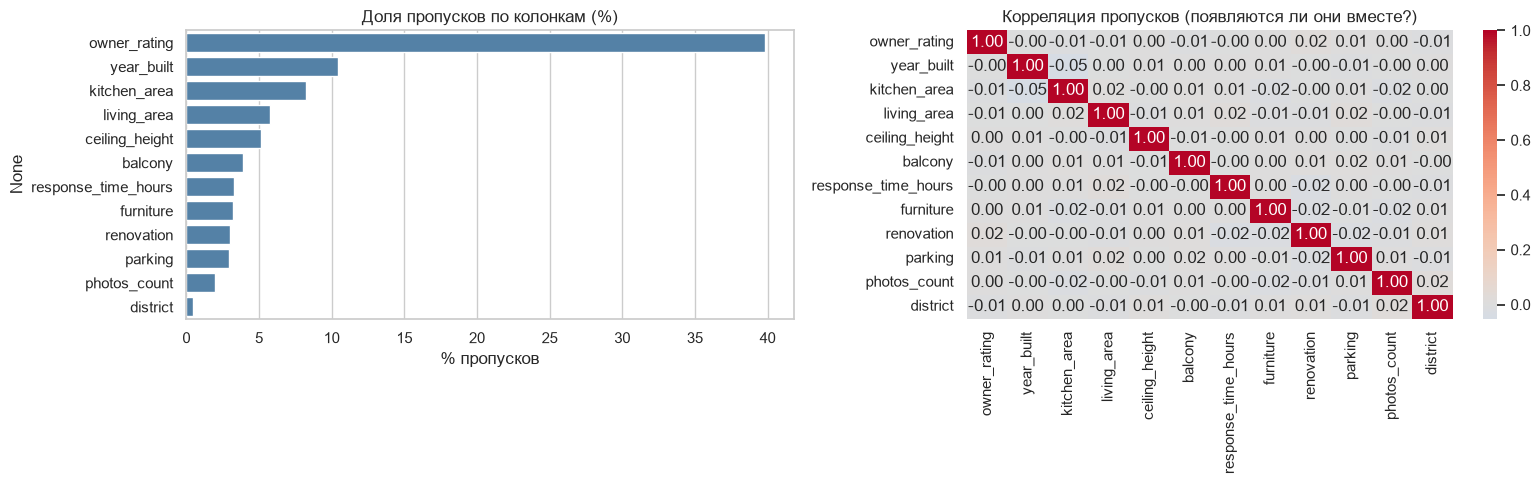

In [78]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Таблица пропусков по всем колонкам (где пропусков > 0)
na_count = df_train.isna().sum()
na_pct = (na_count / len(df_train) * 100).round(2)
na_df = pd.DataFrame({"missing_count": na_count, "missing_%": na_pct})
na_df = na_df[na_df["missing_count"] > 0].sort_values("missing_count", ascending=False)

display(na_df)
cols_with_na = na_df.index.tolist()

# 2. Визуализация: барчарт процентов + корреляция пропусков между собой
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(x=na_df["missing_%"], y=na_df.index, ax=axes[0], color="steelblue")
axes[0].set_title("Доля пропусков по колонкам (%)")
axes[0].set_xlabel("% пропусков")

# Корреляция флагов пропусков (1 = пропуск, 0 = заполнено)
na_corr = df_train[cols_with_na].isna().astype(int).corr()
sns.heatmap(na_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Корреляция пропусков (появляются ли они вместе?)")

plt.tight_layout()
plt.show()

Похоже на ситуацию с прошлой лабой, где есть мелкие значения, которые как будто записаны в тысячах, а не в рублях, позже к этому вернёмся.

,column,missing_n,median_if_missing,median_if_present,diff_%,p_value
0,owner_rating,3124,22500.0,22000.0,2.3,0.0009
1,year_built,820,23000.0,22000.0,4.5,0.0105
2,kitchen_area,645,14500.0,23000.0,-37.0,0.0000
3,living_area,454,21750.0,22500.0,-3.3,0.4579
4,ceiling_height,404,22750.0,22500.0,1.1,0.3487
5,balcony,308,21500.0,22500.0,-4.4,0.6917
6,response_time_hours,257,21500.0,22500.0,-4.4,0.4438
7,furniture,254,21000.0,22500.0,-6.7,0.9943
8,renovation,236,23500.0,22000.0,6.8,0.2257
9,parking,231,22000.0,22500.0,-2.2,0.8977


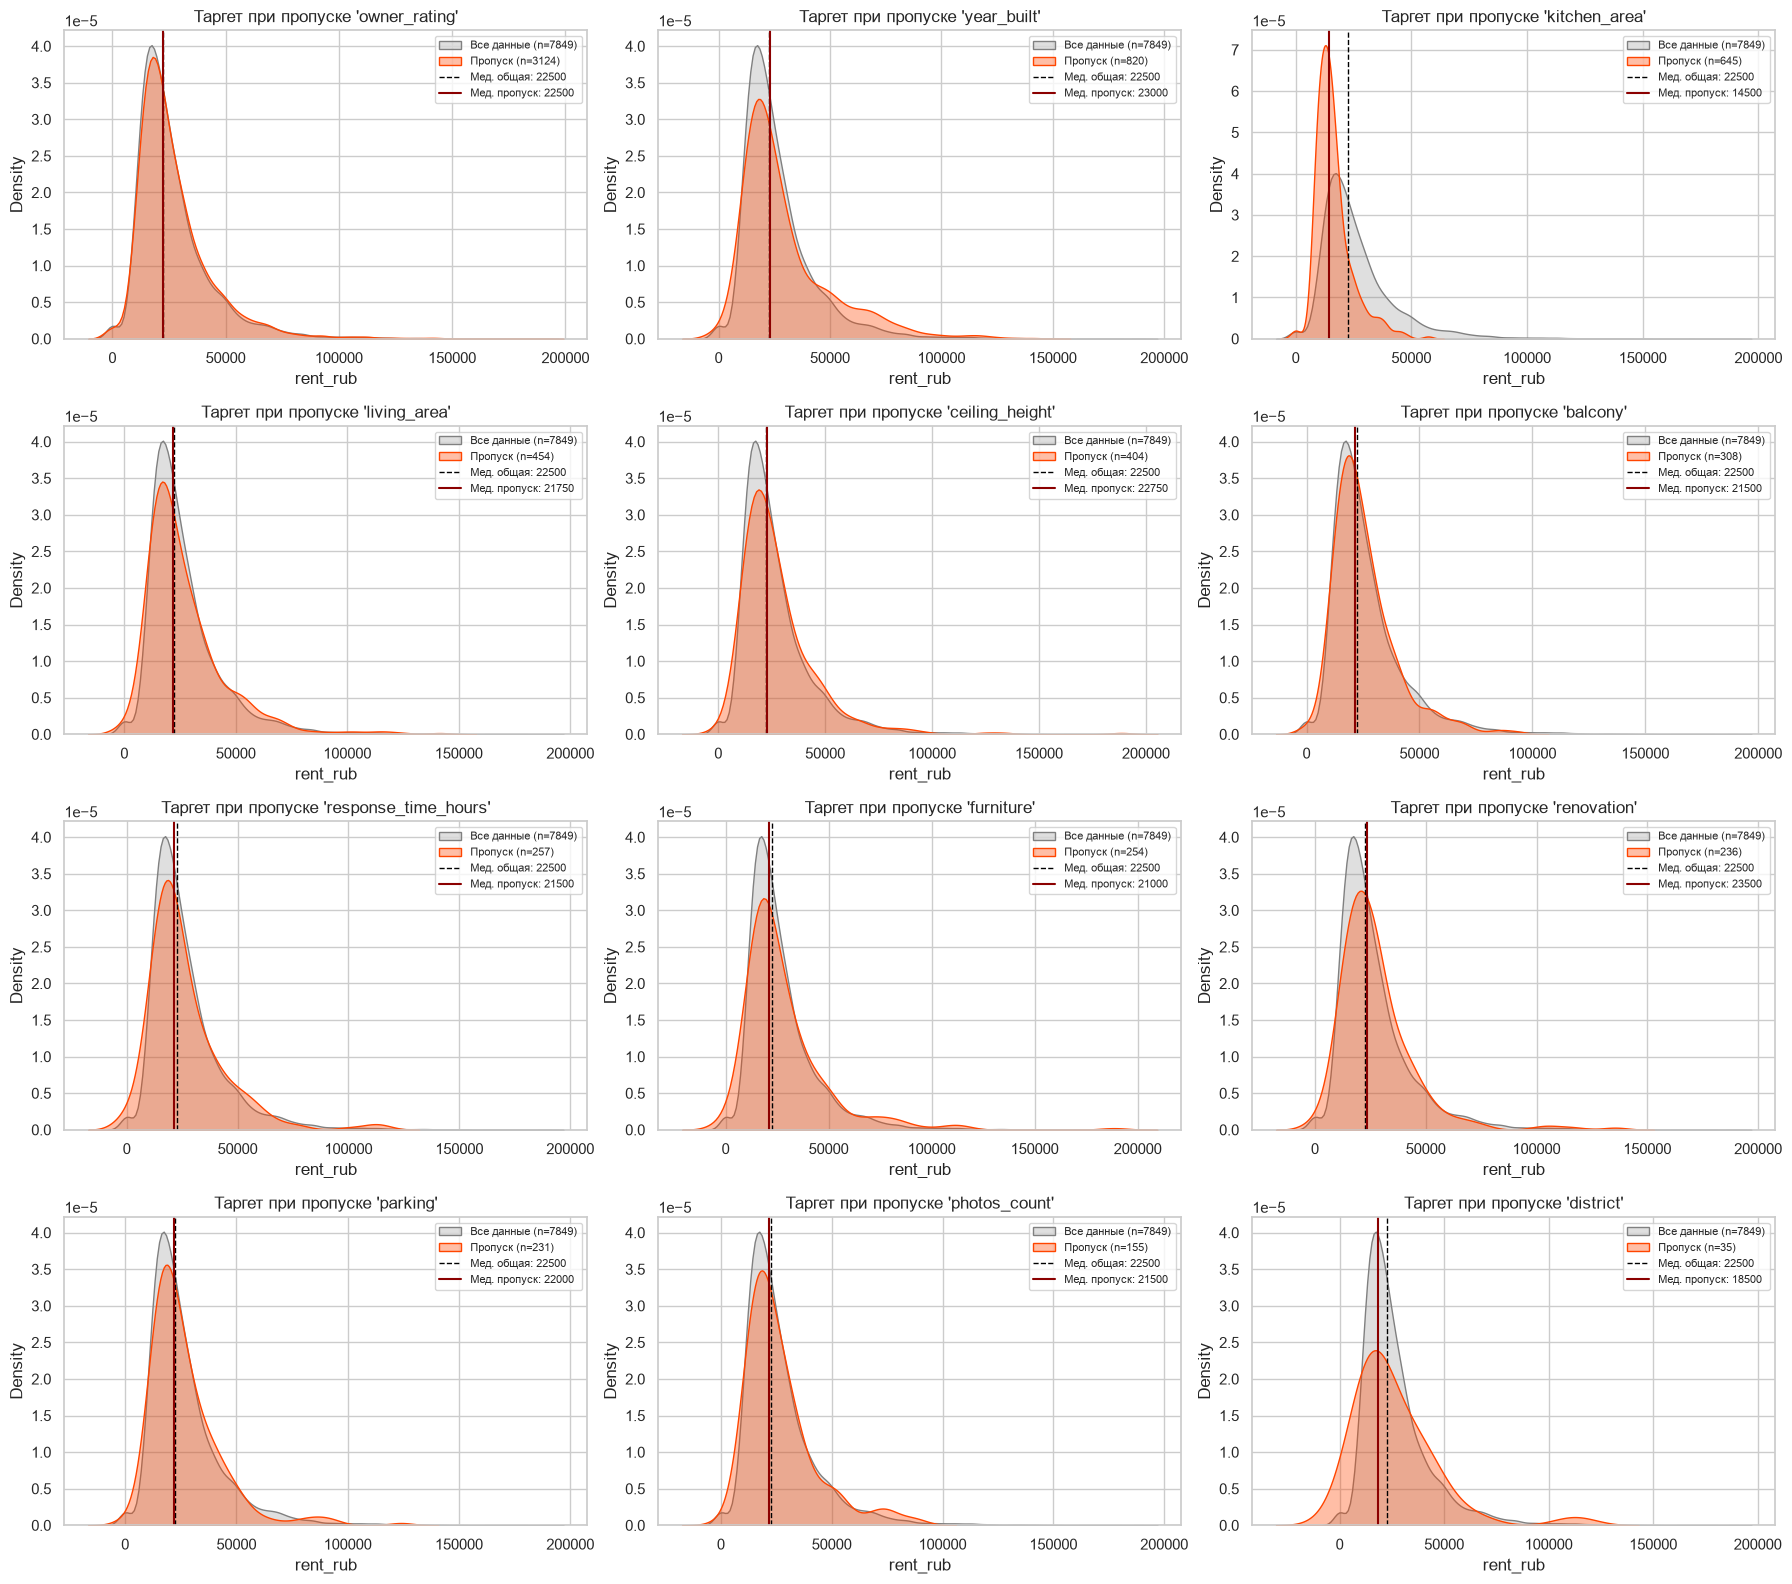

In [79]:
from scipy.stats import mannwhitneyu

# 1. Таблица сравнения медиан таргета: есть пропуск vs нет пропуска
rows_summary = []
for col in cols_with_na:
    mask_na = df_train[col].isna()
    y_miss = df_train.loc[mask_na, "rent_rub"]
    y_pres = df_train.loc[~mask_na, "rent_rub"]
    stat, pval = mannwhitneyu(y_miss, y_pres, alternative="two-sided")
    rows_summary.append({
        "column": col,
        "missing_n": len(y_miss),
        "median_if_missing": y_miss.median(),
        "median_if_present": y_pres.median(),
        "diff_%": round((y_miss.median() - y_pres.median()) / y_pres.median() * 100, 1),
        "p_value": round(pval, 4),
    })

display(pd.DataFrame(rows_summary))

# 2. Сетка графиков: плотность rent_rub для пропусков на фоне всей выборки
n_cols = 3
n_rows = int(np.ceil(len(cols_with_na) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = axes.flatten()

overall_median = df_train["rent_rub"].median()

for i, col in enumerate(cols_with_na):
    ax = axes[i]
    mask_na = df_train[col].isna()
    y_miss = df_train.loc[mask_na, "rent_rub"]
    miss_median = y_miss.median()

    sns.kdeplot(df_train["rent_rub"], ax=ax, fill=True, color="grey", alpha=0.25, label=f"Все данные (n={len(df_train)})")
    sns.kdeplot(y_miss, ax=ax, fill=True, color="orangered", alpha=0.35, label=f"Пропуск (n={len(y_miss)})")

    ax.axvline(overall_median, color="black", linestyle="--", linewidth=1, label=f"Мед. общая: {overall_median:.0f}")
    ax.axvline(miss_median, color="darkred", linestyle="-", linewidth=1.5, label=f"Мед. пропуск: {miss_median:.0f}")

    ax.set_title(f"Таргет при пропуске '{col}'")
    ax.set_xlabel("rent_rub")
    ax.legend(fontsize=8)

# Прячем лишние пустые графики в сетке
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

Подозрения вызывают объявления без указания площади кухни, остальные выглядят вполне естественно. Теперь посмотрим на странные значения и выбросы. 

In [80]:
print("\n--- Логические проверки ---")
print("floor > floors_total:", (df_train["floor"] > df_train["floors_total"]).sum())
print("floor <= 0:", (df_train["floor"] <= 0).sum())
print("living_area > total_area:", (df_train["living_area"] > df_train["total_area"]).sum())
print("kitchen_area > total_area:", (df_train["kitchen_area"] > df_train["total_area"]).sum())
print("living + kitchen > total_area:", ((df_train["living_area"] + df_train["kitchen_area"]) > df_train["total_area"]).sum())
print("rent_rub <= 0:", (df_train["rent_rub"] <= 0).sum())


--- Логические проверки ---
floor > floors_total: 34
floor <= 0: 0
living_area > total_area: 27
kitchen_area > total_area: 0
living + kitchen > total_area: 165
rent_rub <= 0: 0


Видим, что есть следующие проблемы:
1) этаж больше количества этажей(вероятно, перепутали)
2) общая площадь меньше жилой(вероятно, перепутали)
3) общая площадь меньше суммы жилой и кухни
4) нулевая площадь кухни(вероятно, студии)

In [81]:
print("floor > floors_total")
display(df_train[df_train["floor"] > df_train["floors_total"]][
    ["house_type", "year_built", "floor", "floors_total", "rent_rub"]
])

floor > floors_total


,house_type,year_built,floor,floors_total,rent_rub
10539,кирпичный,1963.0,5,4,27000.0
110,кирпичный,2021.0,27,22,34500.0
9664,кирпичный,2025.0,11,10,29000.0
10948,кирпичный,1980.0,12,9,19000.0
2119,панельный,NaN,26,24,23000.0
11163,панельный,1966.0,10,5,14500.0
7690,панельный,1995.0,12,9,15000.0
1744,кирпичный,2009.0,17,15,31500.0
7577,панельный,1977.0,17,16,24000.0
11710,кирпичный,1964.0,10,5,13500.0


In [82]:
# не бывает больше 25 этажей, тут скорее всего промазал по кнопке, поменяю,
# а в остальном ничего такого, просто меняем местами
df_train.loc[df_train["floor"] > 25, "floor"] -= 10
mask = df_train["floor"] > df_train["floors_total"]
df_train.loc[mask, ["floor", "floors_total"]] = df_train.loc[mask, ["floors_total", "floor"]].to_numpy()
print("Осталось ошибок:", (df_train["floor"] > df_train["floors_total"]).sum())

Осталось ошибок: 0


In [83]:
print("living_area > total_area")
display(df_train[df_train["living_area"] > df_train["total_area"]][
    ["rooms", "total_area", "living_area", "kitchen_area", "rent_rub"]
])

print("living_area + kitchen area > total_area")
display(df_train[df_train["living_area"] + df_train["kitchen_area"]> df_train["total_area"]][
    ["rooms", "total_area", "living_area", "kitchen_area", "rent_rub"]
])

living_area > total_area


,rooms,total_area,living_area,kitchen_area,rent_rub
5551,3,55.6,63.2,6.8,24000.0
7147,2,40.0,47.0,6.0,20000.0
3314,3,83.4,113.6,8.3,34000.0
1729,2,50.1,53.8,15.8,28500.0
1980,4,123.3,140.4,0.0,48500.0
4562,3,67.4,92.1,8.4,30000.0
7236,студия,21.1,23.3,NaN,11000.0
3616,1,46.4,50.2,13.6,20000.0
1524,студия,39.9,52.6,NaN,15000.0
581,1,52.7,61.5,8.6,13500.0


living_area + kitchen area > total_area


,rooms,total_area,living_area,kitchen_area,rent_rub
11121,1,41.0,27.4,15.7,16000.0
6547,1,32.1,21.6,17.2,32500.0
1427,1,33.0,19.5,13.9,43500.0
10522,1,30.0,15.4,17.2,15500.0
5551,3,55.6,63.2,6.8,24000.0
...,...,...,...,...,...
11155,1,35.2,19.6,15.7,12500.0
6374,1,32.4,16.2,18.5,27000.0
4358,1,38.6,25.5,16.4,21000.0
10491,2,39.4,25.2,22.0,20500.0


Что то странное, пока поменям местами там, где общая меньше жилой, потом вернёмся в разделе выбросов.

In [84]:
mask = df_train["living_area"] > df_train["total_area"]
df_train.loc[mask, ["living_area", "total_area"]] = df_train.loc[mask, ["total_area", "living_area"]].to_numpy()
print("Осталось ошибок:", (df_train["living_area"] > df_train["total_area"]).sum())

Осталось ошибок: 0


In [85]:
print("Кухня (NaN и 0.0) по числу комнат")
print("Пропуски kitchen_area по rooms:\n", df_train["kitchen_area"].isna().groupby(df_train["rooms"]).sum())
print("Всего студий", (df_train["rooms"] == "студия").sum())
print("Нули kitchen_area (== 0) по rooms:\n", (df_train["kitchen_area"] == 0).groupby(df_train["rooms"]).sum())

Кухня (NaN и 0.0) по числу комнат
Пропуски kitchen_area по rooms:
 rooms
1           0
2           0
3           0
4           0
5           0
студия    645
Name: kitchen_area, dtype: int64
Всего студий 645
Нули kitchen_area (== 0) по rooms:
 rooms
1         75
2         66
3         37
4         16
5          1
студия     0
Name: kitchen_area, dtype: int64


Видим, что у значение NaN стоит только у студий.

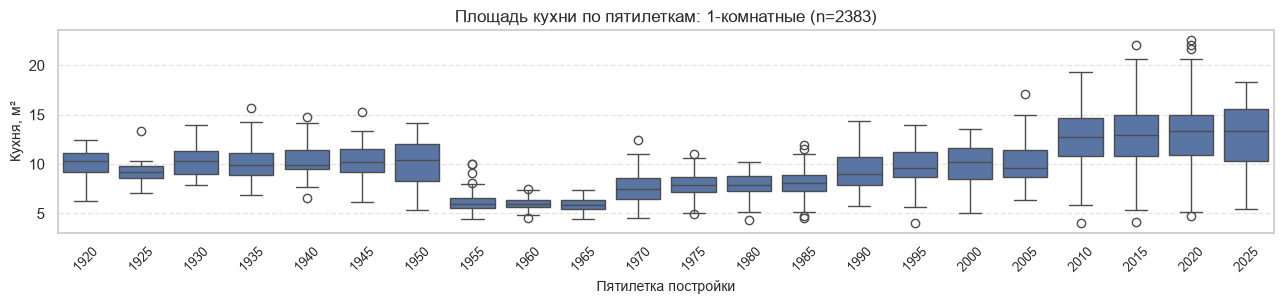

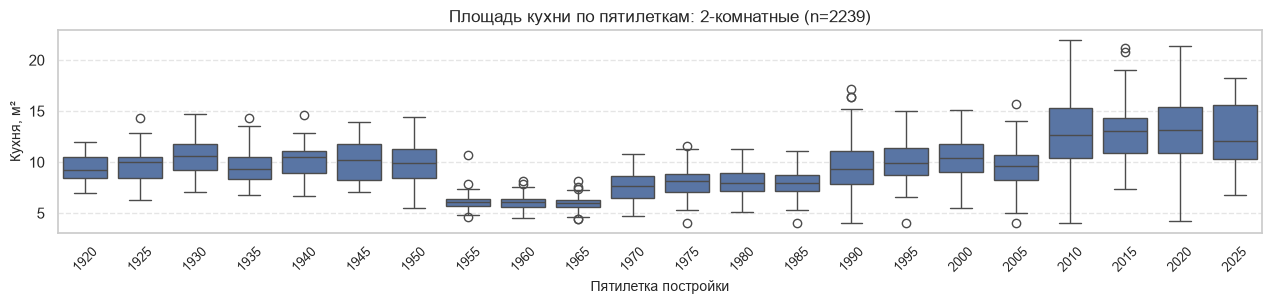

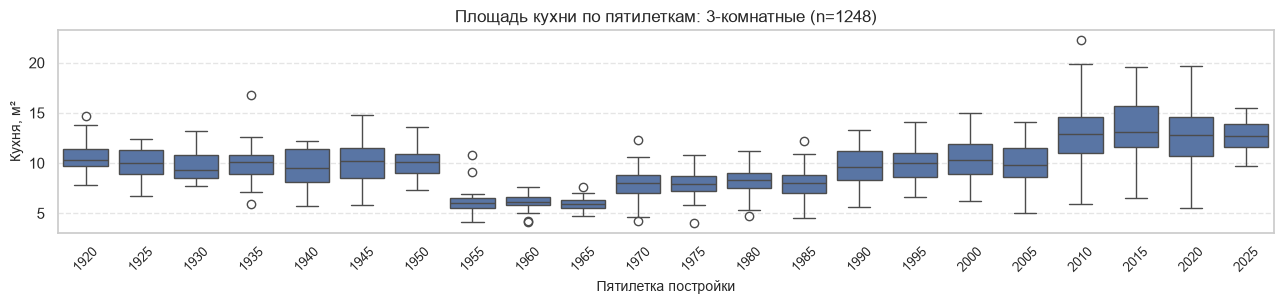

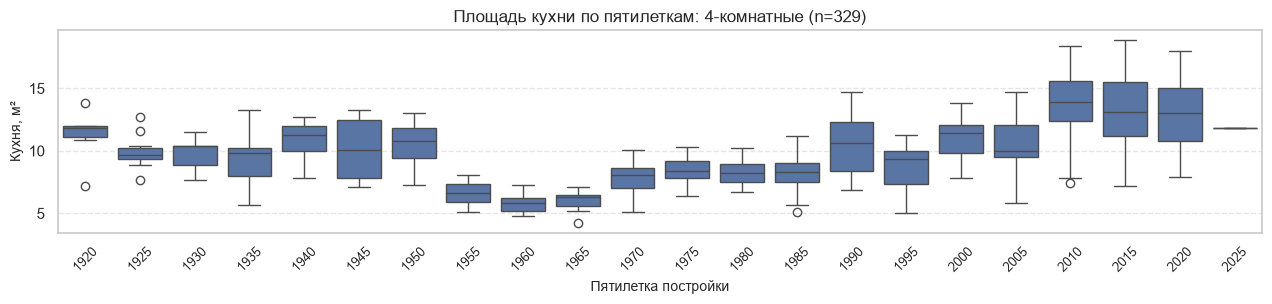

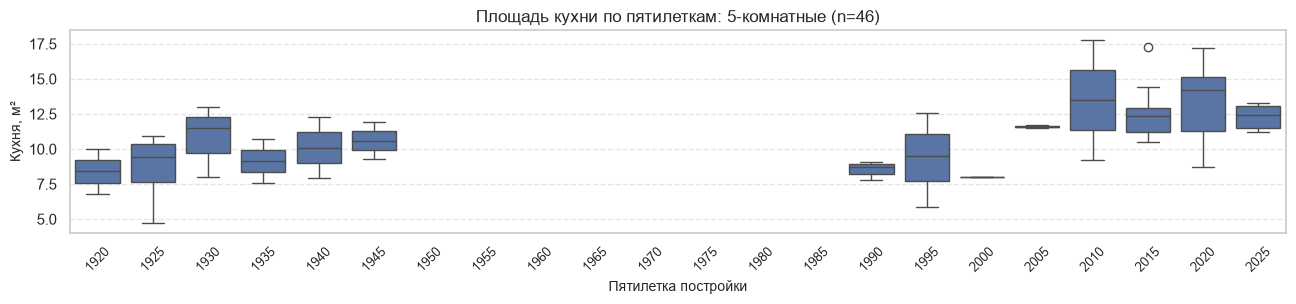

In [86]:
import matplotlib.pyplot as plt
import seaborn as sns

df_k = df_train[(df_train["kitchen_area"] > 0) & (df_train["year_built"].notna())].copy()
df_k["five_year"] = ((df_k["year_built"] // 5) * 5).astype(int)
all_bins = list(range(1920, 2026, 5))

for r in ["1", "2", "3", "4", "5"]:
    sub = df_k[df_k["rooms"] == r]
    fig, ax = plt.subplots(figsize=(13, 3.2))
    sns.boxplot(data=sub, x="five_year", y="kitchen_area", order=all_bins, ax=ax)
    ax.set_title(f"Площадь кухни по пятилеткам: {r}-комнатные (n={len(sub)})", fontsize=12)
    ax.set_xlabel("Пятилетка постройки", fontsize=10)
    ax.set_ylabel("Кухня, м²", fontsize=10)
    ax.tick_params(axis="x", labelsize=9, rotation=45)
    ax.grid(True, axis="y", linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

In [87]:
g = df_k.groupby(["rooms", "five_year"])["kitchen_area"]
q1 = g.transform(lambda s: s.quantile(0.25))
q3 = g.transform(lambda s: s.quantile(0.75))
iqr = q3 - q1

is_outlier = (df_k["kitchen_area"] < q1 - 1.5 * iqr) | (df_k["kitchen_area"] > q3 + 1.5 * iqr)
kitchen_outliers = df_k.loc[is_outlier, [
    "rooms", "five_year", "year_built", "house_type",
    "total_area", "living_area", "kitchen_area", "rent_rub"
]].sort_values(["rooms", "five_year", "kitchen_area"])

print(f"Всего выбросов на боксплотах: {len(kitchen_outliers)}")

with pd.option_context("display.max_rows", 150):
    display(kitchen_outliers)

Всего выбросов на боксплотах: 75


,rooms,five_year,year_built,house_type,total_area,living_area,kitchen_area,rent_rub
6962,1,1925,1927.0,кирпичный,50.8,23.8,13.4,38000.0
1657,1,1935,1937.0,кирпичный,57.6,30.9,15.7,45500.0
6362,1,1940,1940.0,кирпичный,49.7,24.5,6.6,31500.0
8404,1,1940,1941.0,кирпичный,45.7,28.1,14.8,36500.0
7674,1,1945,1947.0,кирпичный,57.9,34.5,15.3,31500.0
10942,1,1955,1955.0,кирпичный,41.1,NaN,8.1,15500.0
2068,1,1955,1955.0,кирпичный,54.3,29.6,9.1,16500.0
7548,1,1955,1955.0,блочный,46.9,29.8,10.0,24000.0
8984,1,1955,1955.0,кирпичный,42.8,22.7,10.0,22500.0
544,1,1960,1963.0,кирпичный,34.5,22.2,4.5,23000.0


Отсюда видно, что площадь кухни сильно зависит от года постройки дома, а также есть определённого рода выбросы по этому показателю, однако я прогуглил и увидел, что кухни в 4 квадратных метра действительно существуют, преимущественно в старых домах, конечно, однако никакие из значений не выглядят фантастическими, поэтому их я удалять или менять не буду. Заменять же пропуски в площадях кухни и жилых площадях буду медианами этих показателей в соответствующей пятилетке.

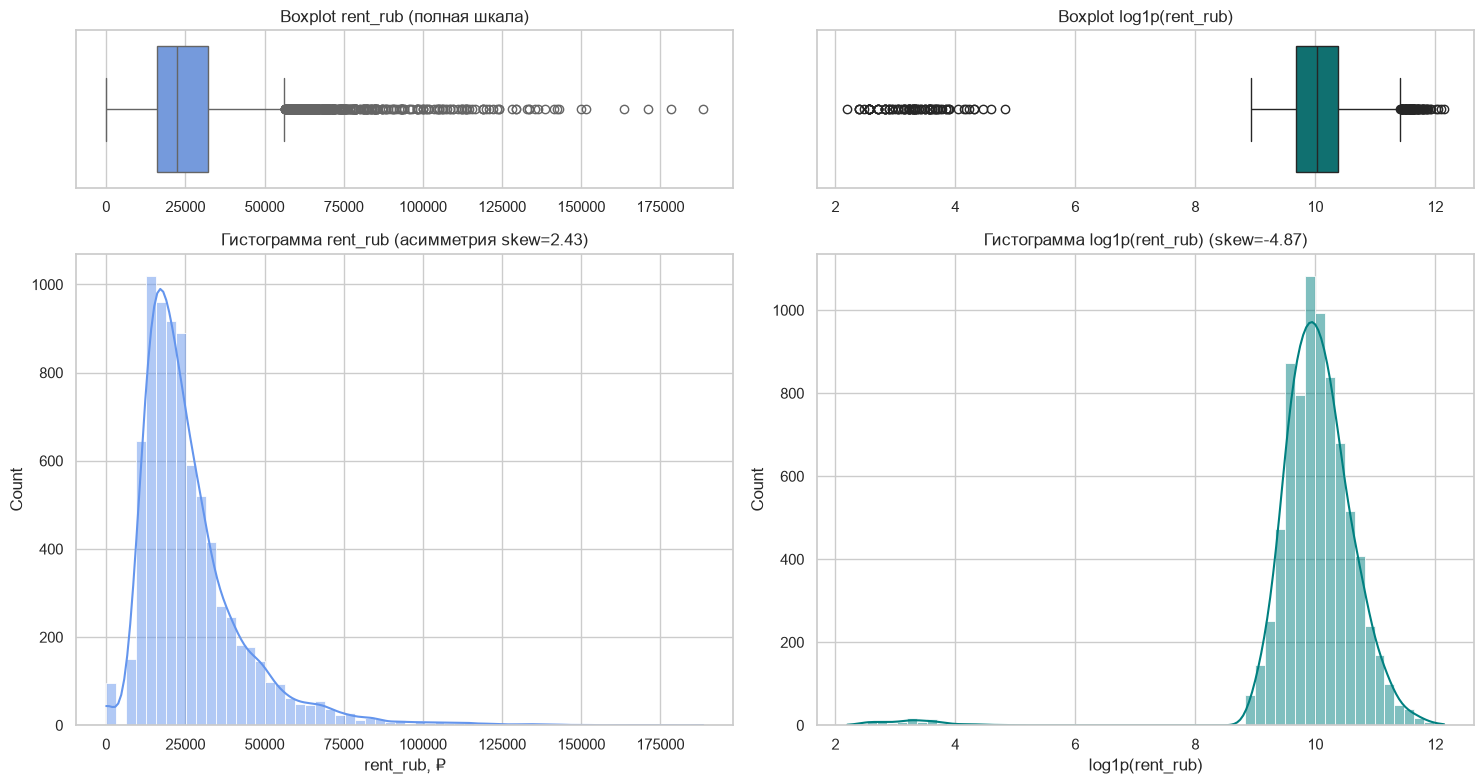

In [88]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8), gridspec_kw={"height_ratios": [1, 3]})

# Слева: обычная шкала rent_rub (полный диапазон!)
sns.boxplot(x=df_train["rent_rub"], ax=axes[0, 0], color="cornflowerblue")
axes[0, 0].set_title("Boxplot rent_rub (полная шкала)")
axes[0, 0].set_xlabel("")

sns.histplot(df_train["rent_rub"], bins=60, kde=True, ax=axes[1, 0], color="cornflowerblue")
axes[1, 0].set_title(f"Гистограмма rent_rub (асимметрия skew={df_train['rent_rub'].skew():.2f})")
axes[1, 0].set_xlabel("rent_rub, ₽")

# Справа: логарифм log1p(rent_rub) — видна и нормальность, и выбросы < 1000
log_target = np.log1p(df_train["rent_rub"])
sns.boxplot(x=log_target, ax=axes[0, 1], color="teal")
axes[0, 1].set_title("Boxplot log1p(rent_rub)")
axes[0, 1].set_xlabel("")

sns.histplot(log_target, bins=60, kde=True, ax=axes[1, 1], color="teal")
axes[1, 1].set_title(f"Гистограмма log1p(rent_rub) (skew={log_target.skew():.2f})")
axes[1, 1].set_xlabel("log1p(rent_rub)")

plt.tight_layout()
plt.show()

In [89]:
low_rent = df_train[df_train["rent_rub"] < 1000]
print(f"Количество: rent_rub < 1000 руб {len(low_rent)} ({len(low_rent)/len(df_train)*100:.2f}%)")
print("Диапазон < 1000:", low_rent["rent_rub"].min(), "—", low_rent["rent_rub"].max())
print("Значения от 500 до 8000:", sorted(df_train[(df_train["rent_rub"] >= 500) & (df_train["rent_rub"] < 8000)]["rent_rub"].tolist()))
display(low_rent[["district", "rooms", "total_area", "renovation", "rent_rub"]].head(10))

Количество: rent_rub < 1000 руб 96 (1.22%)
Диапазон < 1000: 8.0 — 124.0
Значения от 500 до 8000: [7500.0]


,district,rooms,total_area,renovation,rent_rub
7939,Лесной,1,29.7,косметический,12.0
5659,Кировский,2,57.7,евроремонт,24.0
8724,Промышленный,3,68.1,евроремонт,26.0
7243,Заречный,2,65.6,Косметический,25.0
6621,Железнодорожный,2,50.3,Евроремонт,32.0
1913,Ленинский,2,38.0,евроремонт,22.0
3074,Кировский,студия,29.3,косметический,24.0
10789,Первомайский,1,35.9,без ремонта,12.0
8150,Ленинский,1,30.1,косметический,17.0
8005,Советский,2,59.7,без ремонта,24.0


Тут явно невнимательно прочитали и поставили цену в тысячах рублей, а не в рублях, сейчас исправим. Больше выбросов не видно.

In [90]:
df_train.loc[df_train["rent_rub"] < 1000, "rent_rub"] *= 1000
print("Мин. цена после исправления:", df_train["rent_rub"].min())

Мин. цена после исправления: 7500.0


А теперь посмотрим на другие числовые признаки и выбросы.

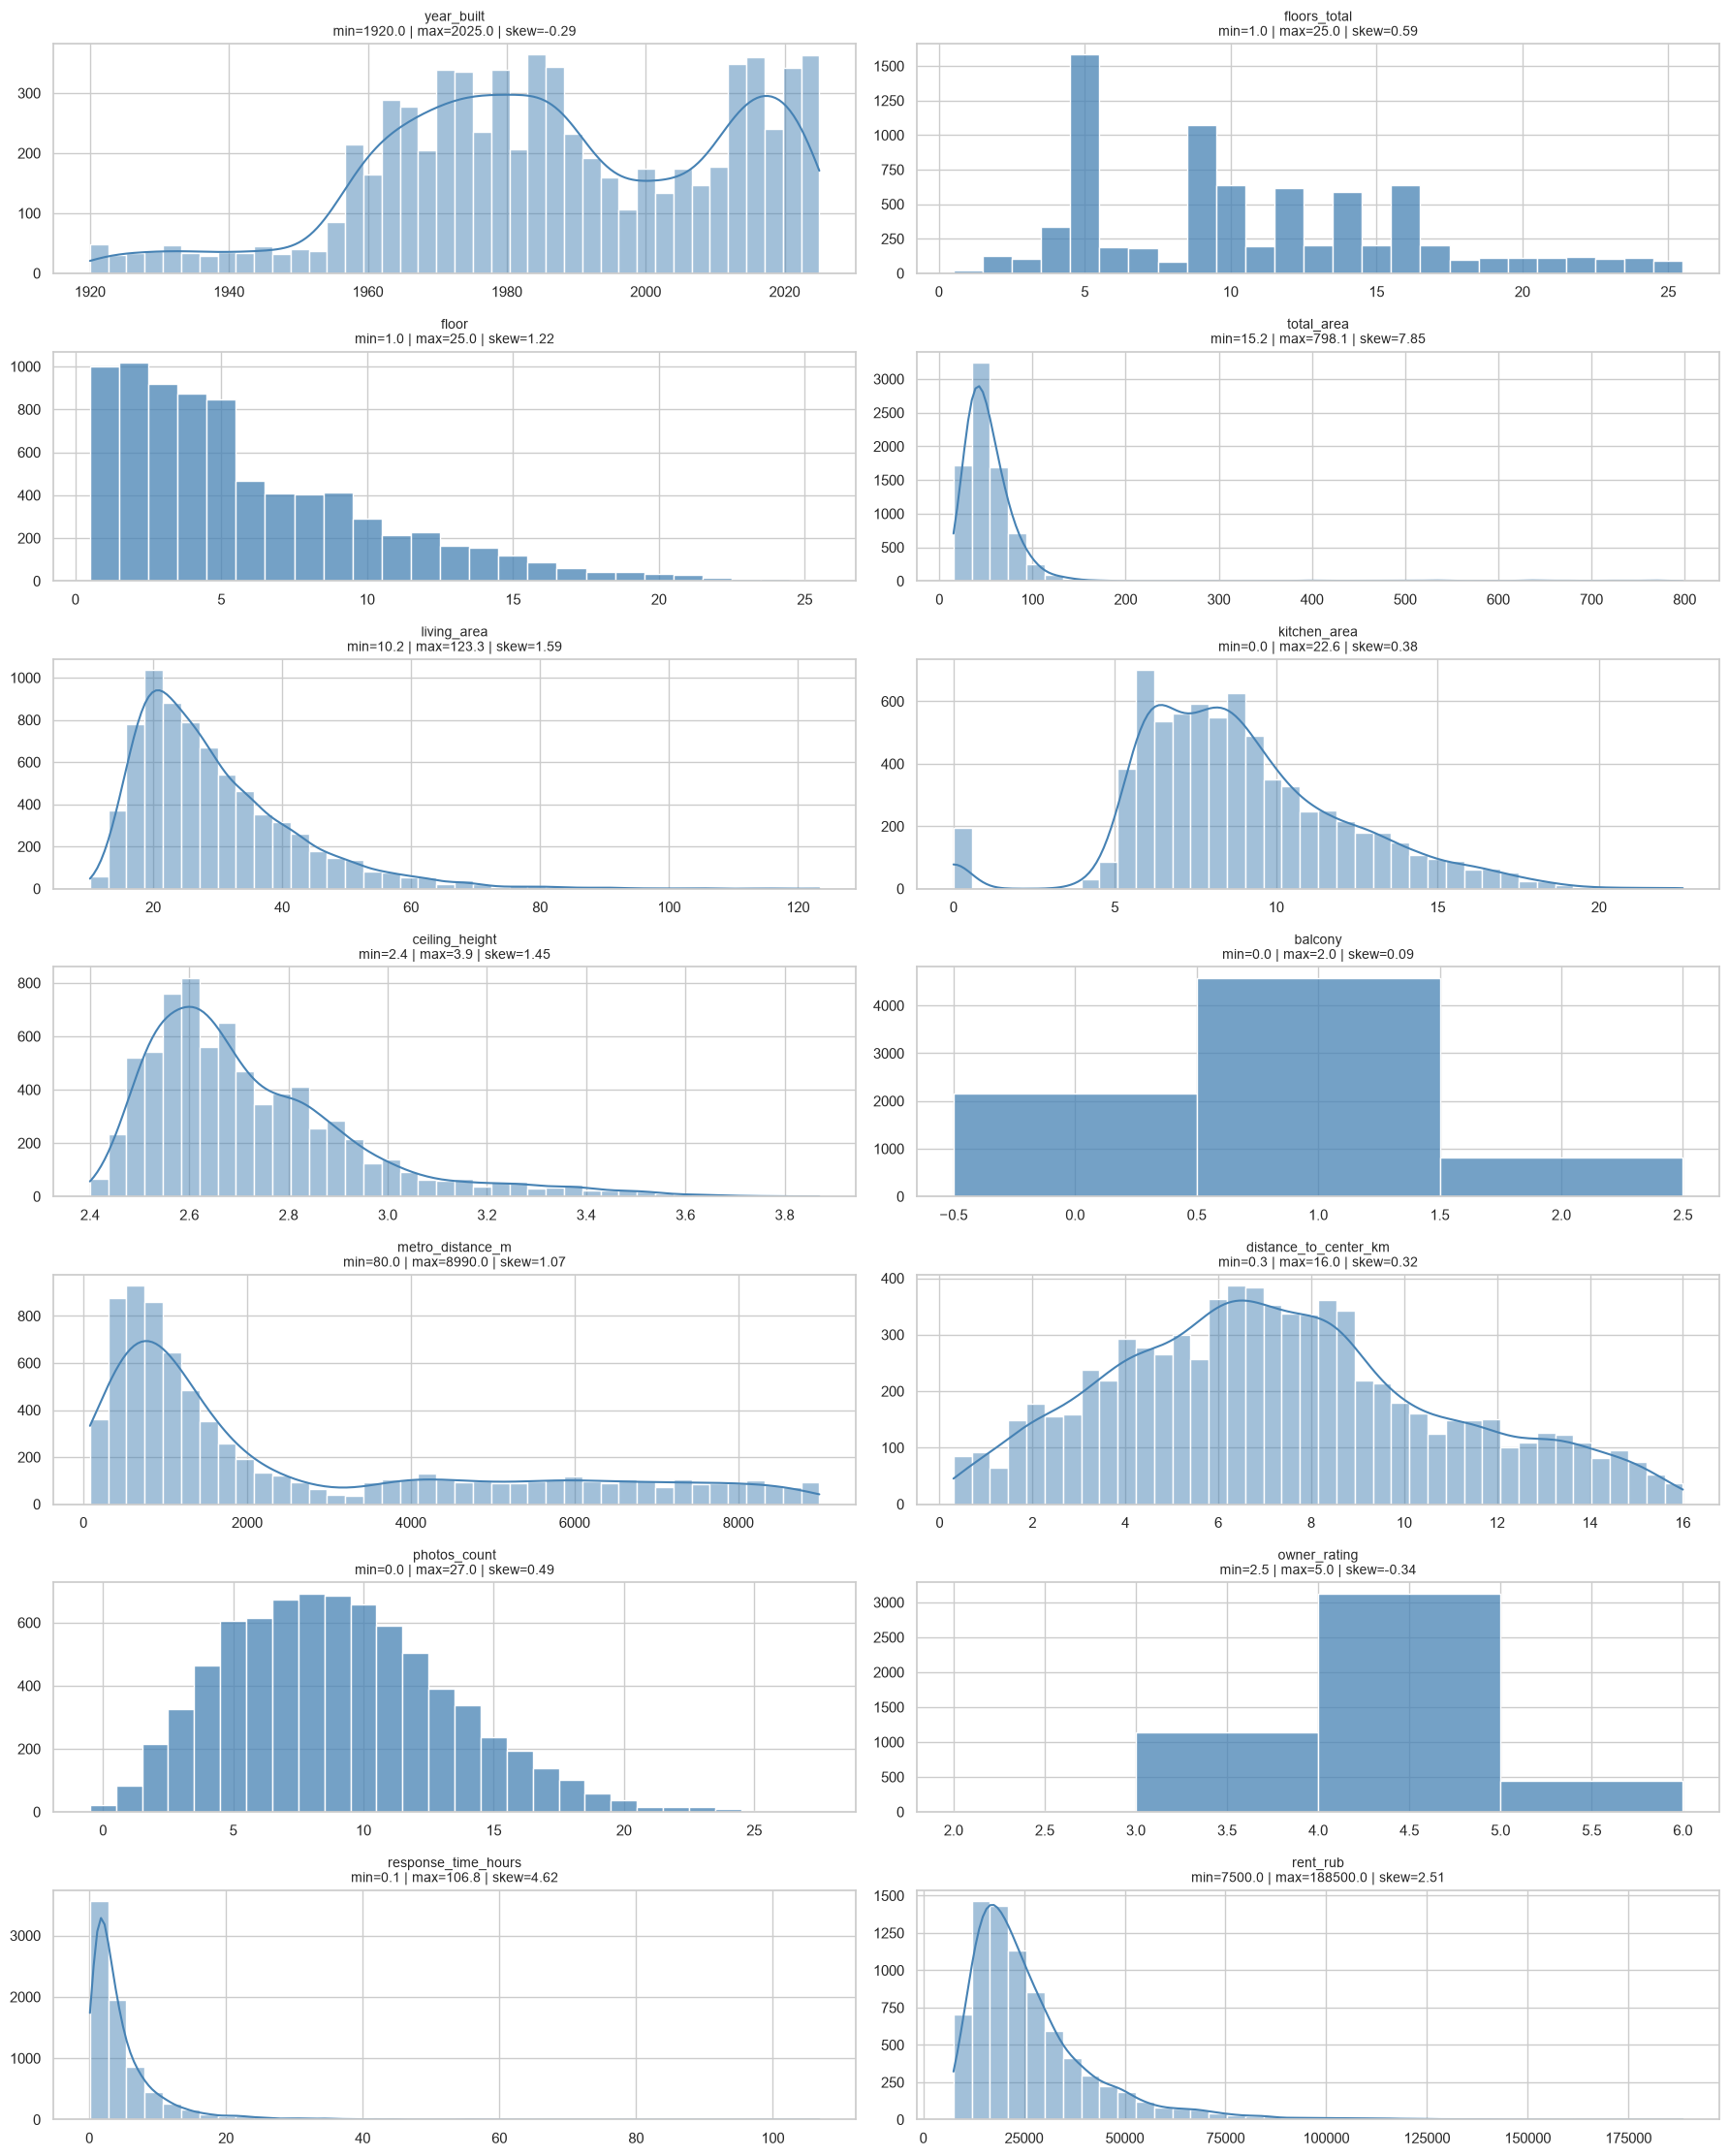

In [91]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = df_train.select_dtypes(include="number").columns.tolist()
n_cols = 2
n_rows = int(np.ceil(len(num_cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 3.2 * n_rows))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    ax = axes[i]
    s = df_train[col].dropna()
    if s.nunique() <= 30:
        sns.histplot(s, discrete=True, ax=ax, color="steelblue")
    else:
        sns.histplot(s, bins=40, kde=True, ax=ax, color="steelblue")
    ax.set_title(f"{col}\nmin={s.min():.1f} | max={s.max():.1f} | skew={s.skew():.2f}", fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

В целом ничего необычного кроме:
1) нулевой кухни, но это уже было
2) космическая общая площадь при максимальной жилой в 123 квадрата

In [13]:
print("=== 1. Разгадываем total_area > 150 ===")
print("Первые значения от 110 до 350:", sorted(df_train[df_train["total_area"] > 200]["total_area"].tolist())[:100])

big = df_train[df_train["total_area"] > 200]
norm = df_train[df_train["total_area"] <= 200]
print(f"Строк > 200: {len(big)}, мин={big['total_area'].min()}, макс={big['total_area'].max()}")
print("Медиана (total_area / living_area) для <= 200:", (norm["total_area"] / norm["living_area"]).mean().round(2))
print("Медиана (total_area / living_area) для > 200:", (big["total_area"] / big["living_area"]).mean().round(2))

print("\n=== 2. Пропуски owner_rating по seller_type ===")
print(df_train["owner_rating"].isna().groupby(df_train["seller_type"]).value_counts())

print("\n=== 3. Даты публикаций и пробелы в renovation ===")
pub_dt = pd.to_datetime(df_train["publication_date"], format="%d.%m.%Y %H:%M", errors="coerce")
print("Даты:", pub_dt.min(), "—", pub_dt.max(), "| Битых дат:", pub_dt.isna().sum())
print("Уникальные renovation:", [repr(x) for x in df_train["renovation"].dropna().unique()])

=== 1. Разгадываем total_area > 150 ===
Первые значения от 110 до 350: [350.2, 354.2, 355.4, 366.5, 388.6, 390.7, 391.1, 391.1, 391.6, 391.8, 393.8, 399.7, 407.3, 412.1, 413.2, 426.6, 428.1, 432.9, 433.4, 444.3, 453.0, 455.6, 455.8, 456.5, 461.0, 462.3, 474.6, 477.5, 489.7, 492.8, 498.6, 510.1, 510.6, 512.0, 523.5, 524.7, 525.1, 527.4, 530.5, 532.7, 533.6, 536.4, 541.7, 542.5, 542.9, 545.6, 547.5, 563.9, 570.0, 589.7, 593.7, 594.9, 595.7, 620.8, 623.5, 626.3, 629.6, 632.4, 633.4, 633.8, 633.8, 634.3, 634.4, 635.3, 640.5, 649.1, 651.6, 660.6, 662.7, 665.6, 670.1, 675.0, 675.2, 675.5, 676.9, 696.9, 698.7, 704.0, 704.8, 707.0, 712.3, 715.3, 720.6, 722.8, 724.5, 731.3, 735.1, 742.4, 742.5, 754.4, 758.0, 763.1, 763.2, 764.0, 766.8, 768.7, 769.3, 771.3, 774.2, 775.2]
Строк > 200: 102, мин=350.2, макс=798.1
Медиана (total_area / living_area) для <= 200: 1.76
Медиана (total_area / living_area) для > 200: 23.32

=== 2. Пропуски owner_rating по seller_type ===
seller_type  owner_rating
агентство

Категории ремонта после очистки: {'космический': 3280, 'евроремонт': 2094, 'без ремонта': 1528, 'дизайнерский': 711, nan: 236}


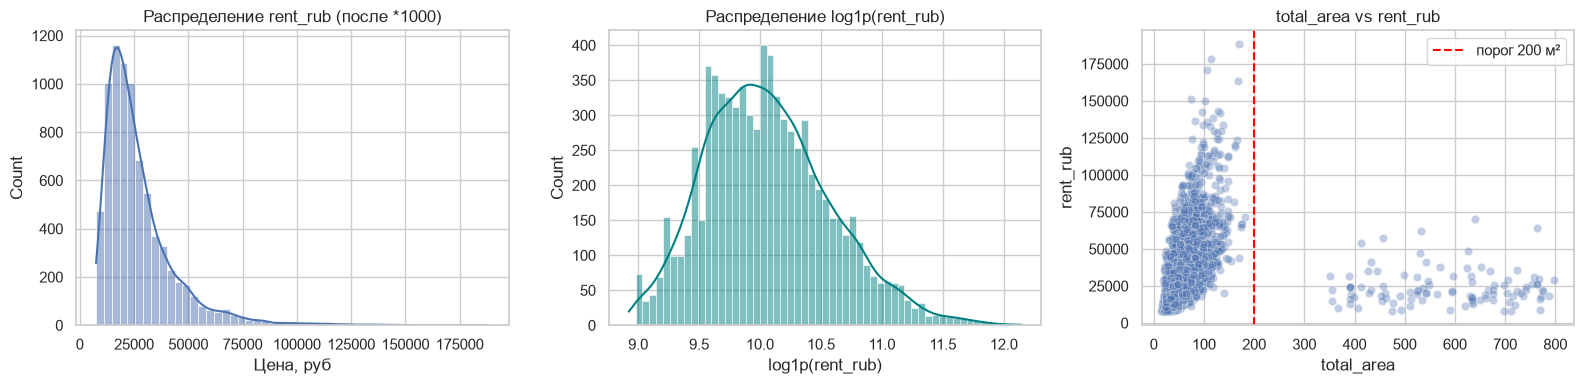

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Делаем временную копию df_train для графиков
df_eda = df_train.copy()
df_eda.loc[df_eda["rent_rub"] < 1000, "rent_rub"] *= 1000

def clean_renovation_text(val):
    if pd.isna(val):
        return np.nan
    s = str(val).strip().lower()
    if "косм" in s:
        return "космический"
    if "евро" in s:
        return "евроремонт"
    if "дизайн" in s or "автор" in s:
        return "дизайнерский"
    if "без" in s or "нет" in s or "треб" in s:
        return "без ремонта"
    return s

df_eda["renovation_clean"] = df_eda["renovation"].apply(clean_renovation_text)
print("Категории ремонта после очистки:", df_eda["renovation_clean"].value_counts(dropna=False).to_dict())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df_eda["rent_rub"], bins=50, kde=True, ax=axes[0])
axes[0].set_title("Распределение rent_rub (после *1000)")
axes[0].set_xlabel("Цена, руб")

sns.histplot(np.log1p(df_eda["rent_rub"]), bins=57, kde=True, ax=axes[1], color="teal")
axes[1].set_title("Распределение log1p(rent_rub)")
axes[1].set_xlabel("log1p(rent_rub)")

# Смотрим, как связаны total_area и rent_rub (обычные vs > 200)
sns.scatterplot(data=df_eda, x="total_area", y="rent_rub", alpha=0.35, ax=axes[2])
axes[2].axvline(200, color="red", linestyle="--", label="порог 200 м²")
axes[2].set_title("total_area vs rent_rub")
axes[2].legend()

plt.tight_layout()
plt.show()

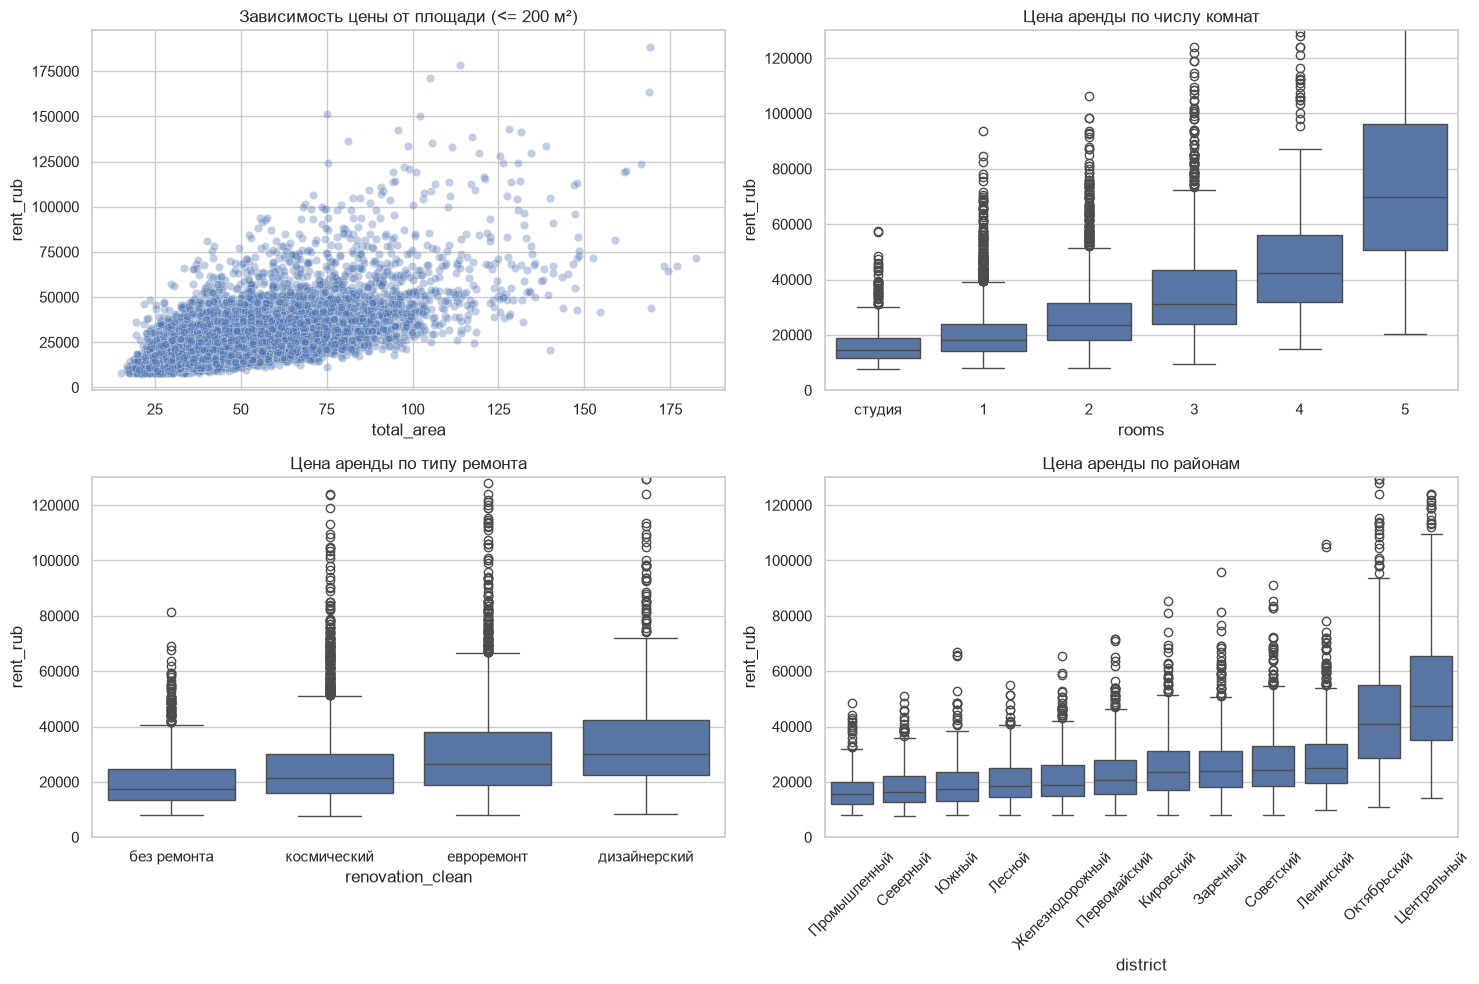

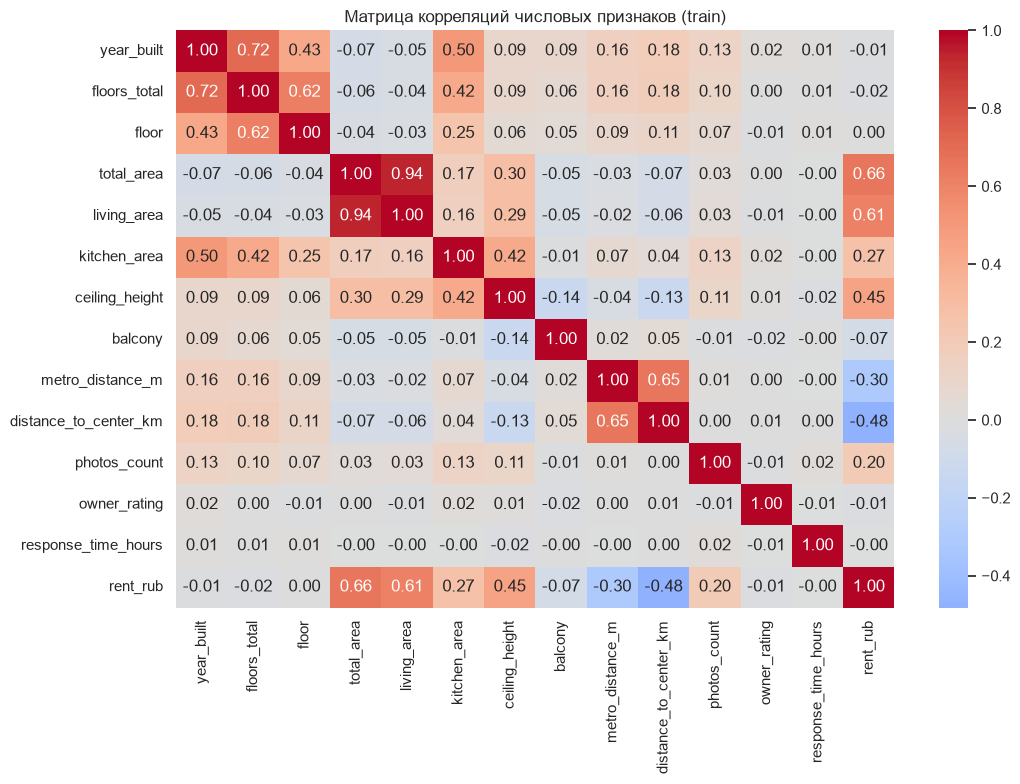

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Площадь (нормальная <= 200) vs Цена
sns.scatterplot(data=df_eda[df_eda["total_area"] <= 200], x="total_area", y="rent_rub", alpha=0.35, ax=axes[0, 0])
axes[0, 0].set_title("Зависимость цены от площади (<= 200 м²)")

# 2. Число комнат vs Цена (увидим, где студия относительно 1-комн!)
rooms_order = ["студия", "1", "2", "3", "4", "5"]
sns.boxplot(data=df_eda, x="rooms", y="rent_rub", order=rooms_order, ax=axes[0, 1])
axes[0, 1].set_title("Цена аренды по числу комнат")
axes[0, 1].set_ylim(0, 130000)

# 3. Ремонт vs Цена
ren_order = ["без ремонта", "космический", "евроремонт", "дизайнерский"]
sns.boxplot(data=df_eda, x="renovation_clean", y="rent_rub", order=ren_order, ax=axes[1, 0])
axes[1, 0].set_title("Цена аренды по типу ремонта")
axes[1, 0].set_ylim(0, 130000)

# 4. Район vs Цена
dist_order = df_eda.groupby("district")["rent_rub"].median().sort_values().index
sns.boxplot(data=df_eda, x="district", y="rent_rub", order=dist_order, ax=axes[1, 1])
axes[1, 1].set_title("Цена аренды по районам")
axes[1, 1].tick_params(axis="x", rotation=45)
axes[1, 1].set_ylim(0, 130000)

plt.tight_layout()
plt.show()

# Тепловая карта корреляций (на нормальных площадях <= 200, чтобы выбросы не портили корреляцию)
plt.figure(figsize=(11, 8))
num_cols = df_eda.select_dtypes(include="number").columns
corr = df_eda[df_eda["total_area"] <= 200][num_cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Матрица корреляций числовых признаков (train)")
plt.tight_layout()
plt.show()

In [16]:
# 1. Смотрим те самые 27 дублей без ID и даты (сначала убрав 180 точных копий)
df_no_exact = df_raw.drop_duplicates()
cols_no_id_date = [c for c in df_no_exact.columns if c not in ["listing_id", "publication_date"]]
hidden_dups = df_no_exact[df_no_exact.duplicated(subset=cols_no_id_date, keep=False)].sort_values(
    by=["total_area", "rent_rub", "publication_date"]
)
print("Строк в скрытых дублях (пары без учёта ID и даты):", len(hidden_dups))
display(hidden_dups[["listing_id", "publication_date", "district", "rooms", "total_area", "living_area", "rent_rub"]].head(12))

# 2. Проверяем: total_area > 200 коррелирует с жилой площадью и ценой, или это случайный шум?
big = df_eda[df_eda["total_area"] > 200]
print("\nВнутри группы total_area > 200 (n =", len(big), "):")
print("Корреляция total_area с living_area:", round(big["total_area"].corr(big["living_area"]), 3))
print("Корреляция total_area с rent_rub:   ", round(big["total_area"].corr(big["rent_rub"]), 3))
print("Если поделить на 10 -> мин/макс:", round((big["total_area"]/10).min(), 1), "—", round((big["total_area"]/10).max(), 1))
display(big[["rooms", "total_area", "living_area", "kitchen_area", "rent_rub"]].head(6))

Строк в скрытых дублях (пары без учёта ID и даты): 54


,listing_id,publication_date,district,rooms,total_area,living_area,rent_rub
9274,KV-937245,07.10.2026 20:59,Северный,студия,27.1,18.7,NaN
10839,KV-587341,24.10.2026 20:59,Северный,студия,27.1,18.7,NaN
3667,KV-621722,13.10.2026 01:52,Южный,студия,27.6,18.2,14500.0
2458,KV-579142,28.09.2026 01:52,Южный,студия,27.6,18.2,14500.0
7764,KV-919336,18.10.2026 16:16,Лесной,1,29.9,18.8,10000.0
5116,KV-139099,26.10.2026 16:16,Лесной,1,29.9,18.8,10000.0
8944,KV-411479,15.10.2026 12:40,Советский,1,33.2,18.8,35000.0
11612,KV-457140,29.10.2026 12:40,Советский,1,33.2,18.8,35000.0
7365,KV-335155,19.09.2026 11:12,Советский,1,34.1,17.0,14500.0
1719,KV-636467,24.09.2026 11:12,Советский,1,34.1,17.0,14500.0



Внутри группы total_area > 200 (n = 102 ):
Корреляция total_area с living_area: 0.004
Корреляция total_area с rent_rub:    -0.008
Если поделить на 10 -> мин/макс: 35.0 — 79.8


,rooms,total_area,living_area,kitchen_area,rent_rub
5167,2,626.3,27.0,11.6,48500.0
6952,2,662.7,26.3,7.9,17000.0
8308,1,696.9,15.2,6.8,8000.0
10121,1,715.3,26.6,8.0,18000.0
3049,4,670.1,43.9,10.5,35000.0
6049,2,769.3,28.8,6.1,16500.0
